# Practical Tutorial: Lasso Regression for Future-Proof ML Engineers

Lasso (Least Absolute Shrinkage and Selection Operator) Regression is a fundamental linear regression technique that uses **L1 regularization**.

### Why is Lasso essential for ML Engineers?
1. **Feature Selection:** Unlike Ridge (L2), Lasso can shrink coefficients completely to zero, effectively acting as an automated feature selection method.
2. **Interpretability:** By producing sparse models (models with fewer non-zero weights), Lasso helps identify the most dominant signals in high-dimensional datasets.
3. **Overfitting Prevention:** It penalizes complexity, making your models more robust and generalized to unseen data.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LassoCV
from sklearn.metrics import mean_squared_error, r2_score

# Generate a synthetic dataset with many redundant features
np.random.seed(42)
n_samples = 150
n_features = 15

X = np.random.randn(n_samples, n_features)

# Only 3 features will truly impact the target variable
true_coefficients = np.zeros(n_features)
true_coefficients[0] = 5.0
true_coefficients[1] = -3.5
true_coefficients[2] = 2.0

# Calculate target with noise
y = np.dot(X, true_coefficients) + np.random.normal(0, 1.5, size=n_samples)

# Convert to DataFrame for readability
feature_names = [f'feature_{i}' for i in range(n_features)]
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

display(df.head())

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,target
0,0.496714,-0.138264,0.647689,1.523030,-0.234153,-0.234137,1.579213,0.767435,-0.469474,0.542560,-0.463418,-0.465730,0.241962,-1.913280,-1.724918,4.071549
1,-0.562288,-1.012831,0.314247,-0.908024,-1.412304,1.465649,-0.225776,0.067528,-1.424748,-0.544383,0.110923,-1.150994,0.375698,-0.600639,-0.291694,3.628698
2,-0.601707,1.852278,-0.013497,-1.057711,0.822545,-1.220844,0.208864,-1.959670,-1.328186,0.196861,0.738467,0.171368,-0.115648,-0.301104,-1.478522,-11.695265
3,-0.719844,-0.460639,1.057122,0.343618,-1.763040,0.324084,-0.385082,-0.676922,0.611676,1.031000,0.931280,-0.839218,-0.309212,0.331263,0.975545,0.109126
4,-0.479174,-0.185659,-1.106335,-1.196207,0.812526,1.356240,-0.072010,1.003533,0.361636,-0.645120,0.361396,1.538037,-0.035826,1.564644,-2.619745,-5.837325


### Step 2: Scale the Data and Train-Test Split
Regularization is highly sensitive to the scale of your features. We must scale features so that the L1 penalty is applied uniformly across all of them.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(df[feature_names], df['target'], test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Step 3: Find the Optimal Regularization Strength (Alpha) via Cross-Validation
The penalty parameter `alpha` controls the strength of the L1 penalty. We use `LassoCV` to automatically perform cross-validation to find the best `alpha` value.

In [13]:
# Search over a range of alpha values
lasso_cv = LassoCV(alphas=np.logspace(-4, 1, 100), cv=5, random_state=42)
lasso_cv.fit(X_train_scaled, y_train)

print(f"Optimal Alpha: {lasso_cv.alpha_:.5f}")

Optimal Alpha: 0.05337


### Step 4: Evaluate and Inspect Feature Selection
Let's analyze the performance of the model on the test set and check which coefficients were successfully set to zero.

In [14]:
# Predict and evaluate
y_pred = lasso_cv.predict(X_test_scaled)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Test MSE: {mse:.4f}")
print(f"Test R2 Score: {r2:.4f}\n")

# Compare Estimated vs. True Coefficients
coeff_df = pd.DataFrame({
    'Feature': feature_names,
    'True Coefficient': true_coefficients,
    'Estimated Coefficient': lasso_cv.coef_
})
display(coeff_df)

Test MSE: 3.1655
Test R2 Score: 0.9402



,Feature,True Coefficient,Estimated Coefficient
0,feature_0,5.0,4.382691
1,feature_1,-3.5,-3.691112
2,feature_2,2.0,1.600984
3,feature_3,0.0,-0.131230
4,feature_4,0.0,0.084219
5,feature_5,0.0,-0.081255
6,feature_6,0.0,0.067780
7,feature_7,0.0,-0.000000
8,feature_8,0.0,-0.064338
9,feature_9,0.0,0.014660


### Step 5: Advanced Hyperparameter Tuning with `GridSearchCV`
While `LassoCV` is highly optimized specifically for Lasso, using `GridSearchCV` is a more general and flexible approach that allows you to easily plug in custom scorers, pipeline steps, and explore different combinations of parameters.

In [15]:
from sklearn.model_selection import GridSearchCV

# Set up a parameter grid
param_grid = {'alpha': np.logspace(-4, 1, 100)}

# Initialize GridSearchCV with Lasso
lasso_grid = GridSearchCV(estimator=Lasso(random_state=42), param_grid=param_grid, cv=5, scoring='neg_mean_squared_error')
lasso_grid.fit(X_train_scaled, y_train)

print(f"Best Alpha from Grid Search: {lasso_grid.best_params_['alpha']:.5f}")
print(f"Best CV Negative MSE: {lasso_grid.best_score_:.4f}")

Best Alpha from Grid Search: 0.05337
Best CV Negative MSE: -2.0781


### Step 6: Visualizing the Regularization Path (Coefficient Decay)
One of the best ways to understand Lasso's feature selection capability is by plotting the regularization path. We will track how coefficients shrink towards zero as we increase the constraint penalty `alpha`.

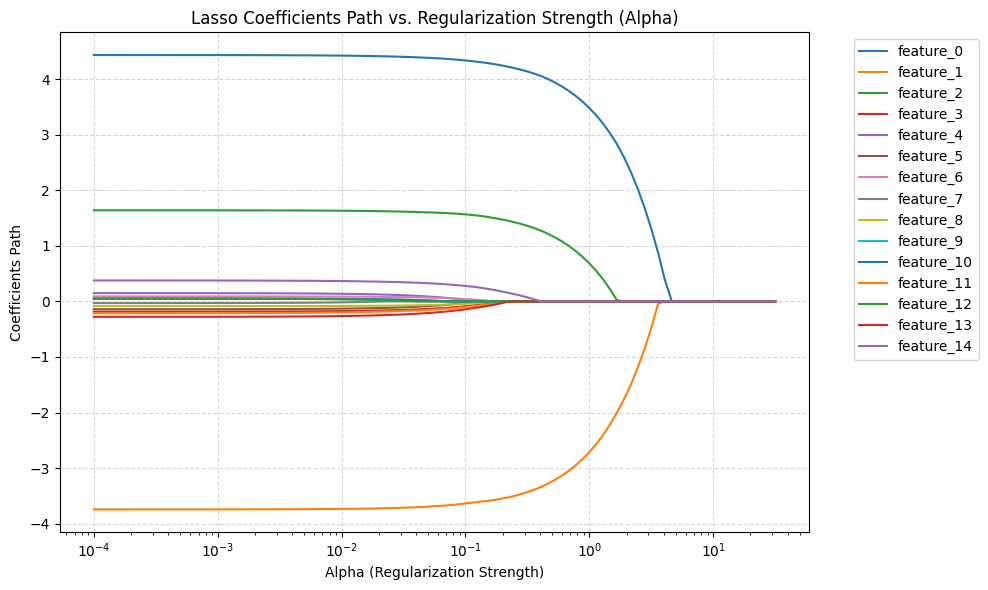

In [16]:
alphas = np.logspace(-4, 1.5, 100)
coefs = []

for a in alphas:
    lasso = Lasso(alpha=a, random_state=42)
    lasso.fit(X_train_scaled, y_train)
    coefs.append(lasso.coef_)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(alphas, coefs)
plt.xscale('log')
plt.xlabel('Alpha (Regularization Strength)')
plt.ylabel('Coefficients Path')
plt.title('Lasso Coefficients Path vs. Regularization Strength (Alpha)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(feature_names, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Step 7: The Future-Proof Upgrade — ElasticNet Regression
ElasticNet introduces a hybrid loss function with both L1 and L2 regularization penalties:

$$\text{Loss} = \text{MSE} + \alpha \cdot \text{l1\_ratio} \cdot ||w||_1 + \frac{\alpha}{2} \cdot (1 - \text{l1\_ratio}) \cdot ||w||_2^2$$

By tuning the `l1_ratio` between `0` (pure Ridge) and `1` (pure Lasso), we can find the absolute optimal balance for feature selection and group-correlation handling.

In [17]:
from sklearn.linear_model import ElasticNet

# Define the ElasticNet parameter grid
elastic_param_grid = {
    'alpha': np.logspace(-4, 1, 50),
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0]
}

# Setup GridSearchCV for ElasticNet
elastic_grid = GridSearchCV(
    estimator=ElasticNet(random_state=42, max_iter=10000),
    param_grid=elastic_param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

elastic_grid.fit(X_train_scaled, y_train)

print(f"Best Parameters: {elastic_grid.best_params_}")
print(f"Best CV Negative MSE: {elastic_grid.best_score_:.4f}")

Best Parameters: {'alpha': np.float64(0.05689866029018299), 'l1_ratio': 1.0}
Best CV Negative MSE: -2.0790


### Step 8: Compare Final Performances
Let's evaluate the tuned ElasticNet model on the test set and compare it to our optimized Lasso model.

In [18]:
best_elastic = elastic_grid.best_estimator_
y_pred_elastic = best_elastic.predict(X_test_scaled)

elastic_mse = mean_squared_error(y_test, y_pred_elastic)
elastic_r2 = r2_score(y_test, y_pred_elastic)

print(f"[Lasso] Test MSE: {mse:.4f} | R2: {r2:.4f}")
print(f"[ElasticNet] Test MSE: {elastic_mse:.4f} | R2: {elastic_r2:.4f}")

[Lasso] Test MSE: 3.1655 | R2: 0.9402
[ElasticNet] Test MSE: 3.1550 | R2: 0.9404


### Step 9: The Ultimate AutoML Pipeline (Multi-Model & Feature Engineering Search)

In professional ML setups, we rarely tune models in isolation. Instead, we build unified processing pipelines.

We will construct a `Pipeline` containing:
1. `StandardScaler` (Normalization)
2. `PolynomialFeatures` (To capture feature interactions)
3. A variable Estimator (Lasso, Ridge, or ElasticNet)

We will configure `GridSearchCV` to automatically determine if we need polynomial features, and which algorithm with what hyperparameter works best overall.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

# Create a base pipeline with a placeholder estimator
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(include_bias=False)),
    ('regressor', Lasso(random_state=42))
])

# Design the parameter grid to search over DIFFERENT model architectures
param_grid = [
    {
        'poly__degree': [1, 2],
        'regressor': [Lasso(random_state=42, max_iter=10000)],
        'regressor__alpha': np.logspace(-3, 1, 10)
    },
    {
        'poly__degree': [1, 2],
        'regressor': [Ridge(random_state=42)],
        'regressor__alpha': np.logspace(-3, 1, 10)
    },
    {
        'poly__degree': [1, 2],
        'regressor': [ElasticNet(random_state=42, max_iter=10000)],
        'regressor__alpha': np.logspace(-3, 1, 10),
        'regressor__l1_ratio': [0.5, 0.9]
    }
]

# Execute the Multi-Model Grid Search
meta_grid = GridSearchCV(pipeline, param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
meta_grid.fit(X_train, y_train)  # Note: fitting raw data since scaling is now handled INSIDE the pipeline!

print("=== BEST MODEL CONFIGURATION ===")
print(meta_grid.best_params_)
print(f"Best CV Score (Neg MSE): {meta_grid.best_score_:.4f}")

=== BEST MODEL CONFIGURATION ===
{'poly__degree': 1, 'regressor': Lasso(max_iter=10000, random_state=42), 'regressor__alpha': np.float64(0.05994842503189409)}
Best CV Score (Neg MSE): -2.0764


### Step 10: Final Model Evaluation on Raw Test Data

In [20]:
# Evaluate the champion model on raw, unseen test data
champion_model = meta_grid.best_estimator_
y_pred_champion = champion_model.predict(X_test)

champion_mse = mean_squared_error(y_test, y_pred_champion)
champion_r2 = r2_score(y_test, y_pred_champion)

print(f"Champion Model Test MSE: {champion_mse:.4f}")
print(f"Champion Model Test R2: {champion_r2:.4f}")

Champion Model Test MSE: 3.1461
Champion Model Test R2: 0.9406
